# Cumulative bits: the cost of learning a room

**Why.** Compression and prediction are the same problem: a code spends about −log₂ p(x | what the receiver already knows) bits on x. An *adaptive* (universal) coder starts without a model of its source, pays extra bits while it learns one, and then codes near the source's rate. For a k-parameter model the extra cost is about (k/2)·log n bits in total, so it shrinks per symbol as the message grows. That is why long texts compress better than short ones.

The adaptive loop is such a coder for the task. While it learns a room it pays with full frames and thumbnails; once settled it sends a 12-byte code plus occasional checks. So the natural measure of readaptation is **bits, not queries**: the cumulative uplink after a move, and its **excess** over what the settled rate would have cost for the same queries. That excess is the price of learning the room. A non-adaptive tag (JPEG) has no learning cost but a fixed rate: a straight line on the cumulative plot. The crossover is where the loop has paid for its learning.

**Definitions.** Per room of a run: *settled rate* = mean uplink bytes per query over the second half of the room's queries in the same run; *excess* = Σ (bytes − settled rate) over the room; *learning time* = the query by which 90% of that excess has been paid. These avoid the fragile "first window within 0.05" recovery time of `readaptation.ipynb`; accuracy over the same halves is shown alongside.

Data: `results/tiered_checks/switch_*` (one pass: room A → Mall tile → room A rearranged), non-adaptive FCOS inputs from `results/teachers/` (as `baselines.ipynb`), and `results/static_room/` (one room replayed 6×).

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve()))
sys.path.insert(0, str(Path('.').resolve()))
from semwisp import piropo
from semwisp.metrics import balanced_accuracy
from tiered_checks import fcos_cutoffs

RES = piropo.REPO / 'results'
TC, TEA, SR = RES / 'tiered_checks', RES / 'teachers', RES / 'static_room'
ROOM = {'room A (training)': 'A', 'room B (mall tile)': 'mall', 'room A, rearranged': 'A2', 'room A, rearranged (test2)': 'A2'}
ROOMS = ['A', 'mall', 'A2']
ROOM_NAME = {'A': 'room A', 'mall': 'Mall tile', 'A2': 'room A rearranged'}
SEQF = {'room A (training)': 'training', 'room B (mall tile)': 'mall_tile',
        'room A, rearranged': 'training_seats', 'room A, rearranged (test2)': 'test2'}
BLUE, ORANGE, AQUA, GRAY, INK, MAGENTA = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984', '#3d3d3a', '#e87ba4'

def load(path):
    z = np.load(path); n = len(z['label'])
    return pd.DataFrame({k: z[k] for k in z.files if k != 'meta' and z[k].shape == (n,)}), json.loads(str(z['meta']))

ADAPT = {'adaptive pixels, raw full': 'switch_fcos_online_pixels_cal_tiered_b200',
         'adaptive pixels, JPEG full': 'switch_fcos_jpeg_online_pixels_cal_tiered_b200',
         'adaptive cells, JPEG full': 'switch_fcos_jpeg_online_cells_cal_tiered_b200',
         'temporal pixels, raw full': 'switch_fcos_online_pixels_cal_temporal_b200',
         'temporal pixels, JPEG full': 'switch_fcos_jpeg_online_pixels_cal_temporal_b200',
         'temporal cells, JPEG full': 'switch_fcos_jpeg_online_cells_cal_temporal_b200'}
runs = {}
for name, run in ADAPT.items():
    if (TC / f'{run}.npz').exists():
        d, _ = load(TC / f'{run}.npz'); d['room'] = d.seq.map(ROOM); runs[name] = d
    else:
        print('missing', run)

# non-adaptive: FCOS on what a fixed tag would send (same frames, same order)
lab = next(iter(runs.values()))[['seq', 't', 'label', 'room']]
pos, neg = fcos_cutoffs(); thr = (pos + neg) / 2
INPUTS = {'full frame': 'fcos_r50@480_s2', 'JPEG q88': 'fcos_r50@480_jpeg160x120q88_s2', 'JPEG q50': 'fcos_r50@480_jpeg160x120q50_s2'}
for name, folder in INPUTS.items():
    parts = []
    for s, f in SEQF.items():
        r = np.load(TEA / folder / f'{f}.npz')
        parts.append(pd.DataFrame({'seq': s, 't': r['t'], 'score': r['score'],
                                   'up_bytes': r['bytes'] if 'bytes' in r.files else np.full(len(r['t']), 19200)}))
    d = lab.merge(pd.concat(parts), on=['seq', 't'], how='left', validate='1:1')
    assert d.score.notna().all()
    d['answer'] = (d.score >= thr).astype(int)
    runs[name] = d
list(runs)

['adaptive pixels, raw full',
 'adaptive pixels, JPEG full',
 'adaptive cells, JPEG full',
 'temporal pixels, raw full',
 'temporal pixels, JPEG full',
 'temporal cells, JPEG full',
 'full frame',
 'JPEG q88',
 'JPEG q50']

## 1. Cumulative uplink over the switch stream

Non-adaptive tags (constant bytes per query) are straight lines. The adaptive runs climb steeply while they learn each room (bootstrap: a full frame every query) and flatten once a code is deployed. The vertical lines mark the two moves.

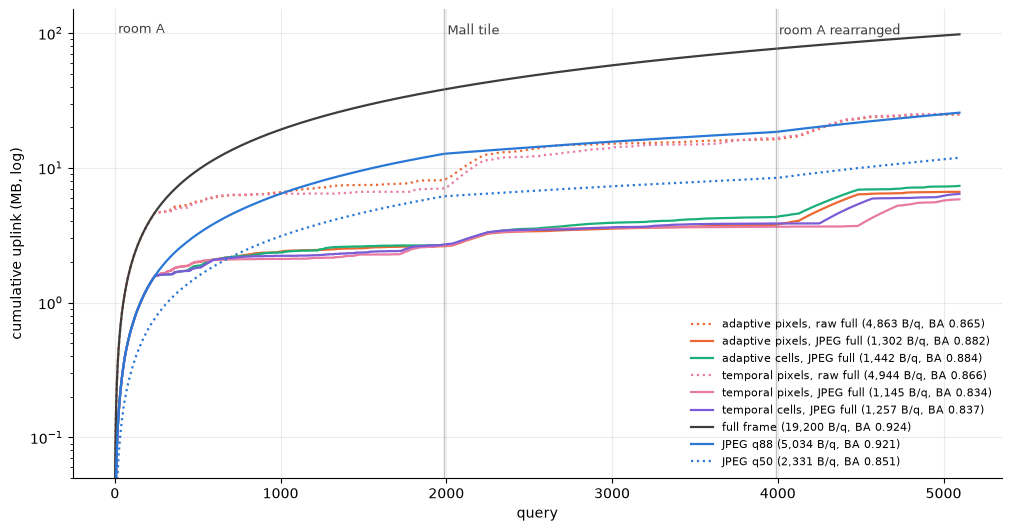

,total_MB,bytes_per_query,balanced_acc,below_JPEG_q88_from
method,,,,
"adaptive pixels, raw full",24.79,"4,863",0.865,4960.000000
"adaptive pixels, JPEG full",6.64,"1,302",0.882,244.000000
"adaptive cells, JPEG full",7.35,"1,442",0.884,244.000000
"temporal pixels, raw full",25.20,"4,944",0.866,5018.000000
"temporal pixels, JPEG full",5.84,"1,145",0.834,244.000000
"temporal cells, JPEG full",6.41,"1,257",0.837,244.000000
full frame,97.86,"19,200",0.924,5097.000000
JPEG q88,25.66,"5,034",0.921,nan
JPEG q50,11.88,"2,331",0.851,0.000000


In [2]:
STYLE = {'full frame': (INK, '-'), 'JPEG q88': (BLUE, '-'), 'JPEG q50': (BLUE, ':'),
         'adaptive pixels, raw full': (ORANGE, ':'), 'adaptive pixels, JPEG full': (ORANGE, '-'),
         'adaptive cells, JPEG full': (AQUA, '-'),
         'temporal pixels, raw full': (MAGENTA, ':'), 'temporal pixels, JPEG full': (MAGENTA, '-'),
         'temporal cells, JPEG full': ('#7a5cd6', '-')}
starts = np.flatnonzero(np.r_[True, lab.room.values[1:] != lab.room.values[:-1]])
fig, ax = plt.subplots(figsize=(10, 5.2), constrained_layout=True)
for name, d in runs.items():
    c, ls = STYLE[name]
    ax.plot(np.cumsum(d.up_bytes.values) / 1e6, color=c, ls=ls, lw=1.6,
            label=f'{name} ({d.up_bytes.mean():,.0f} B/q, BA {balanced_accuracy(d):.3f})')
for s in starts[1:]:
    ax.axvline(s, color=GRAY, lw=1, alpha=0.5)
for r, s in zip(ROOMS, starts):
    ax.text(s + 20, 0.97, ROOM_NAME[r], transform=ax.get_xaxis_transform(), fontsize=9, color=INK, va='top')
ax.set_yscale('log'); ax.set_ylim(0.05, 150)
ax.set_xlabel('query'); ax.set_ylabel('cumulative uplink (MB, log)')
ax.legend(frameon=False, fontsize=8, loc='lower right')
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(alpha=0.25)
plt.show()

ref = np.cumsum(runs['JPEG q88'].up_bytes.values)
rows = []
for name, d in runs.items():
    cum = np.cumsum(d.up_bytes.values)
    above = np.flatnonzero(cum >= ref)
    rows.append(dict(method=name, total_MB=cum[-1] / 1e6, bytes_per_query=d.up_bytes.mean(), balanced_acc=balanced_accuracy(d),
                     below_JPEG_q88_from=None if name == 'JPEG q88' else (0 if len(above) == 0 else int(above[-1] + 1))))
pd.DataFrame(rows).set_index('method').style.format({'total_MB': '{:.2f}', 'bytes_per_query': '{:,.0f}', 'balanced_acc': '{:.3f}'})

## 2. The price of learning each room

Per room: the settled rate, the excess paid while learning (in kB, and in units of a non-adaptive JPEG q88 frame of that room), and the query by which 90% of it was paid. Accuracy in the first and second half of the room is shown alongside, so a cheap learning phase that answers badly is visible.

In [3]:
def room_costs(d, name):
    out = []
    for r in ROOMS:
        g = d[d.room == r].reset_index(drop=True)
        b = g.up_bytes.values.astype(float); n = len(b)
        settled = b[n // 2:].mean()
        ex = np.cumsum(b - settled)
        total = ex[-1]
        t90 = int(np.argmax(ex >= 0.9 * total)) if total > 0 else 0
        jq88 = runs['JPEG q88'][runs['JPEG q88'].room == r].up_bytes.mean()
        out.append(dict(method=name, room=ROOM_NAME[r], queries=n, settled_B=settled, excess_kB=total / 1e3,
                        excess_in_jpeg_frames=total / jq88, learning_time=t90,
                        acc_first_half=balanced_accuracy(g.iloc[:n // 2]), acc_second_half=balanced_accuracy(g.iloc[n // 2:])))
    return out

cost = pd.DataFrame([r for name, d in runs.items() if name.startswith(('adaptive', 'temporal')) for r in room_costs(d, name)])
cost['room'] = pd.Categorical(cost.room, [ROOM_NAME[r] for r in ROOMS], ordered=True)
cost.sort_values('room', kind='stable').set_index(['room', 'method']).style.format(
    {'settled_B': '{:,.0f}', 'excess_kB': '{:,.0f}', 'excess_in_jpeg_frames': '{:,.0f}',
     'acc_first_half': '{:.3f}', 'acc_second_half': '{:.3f}'})

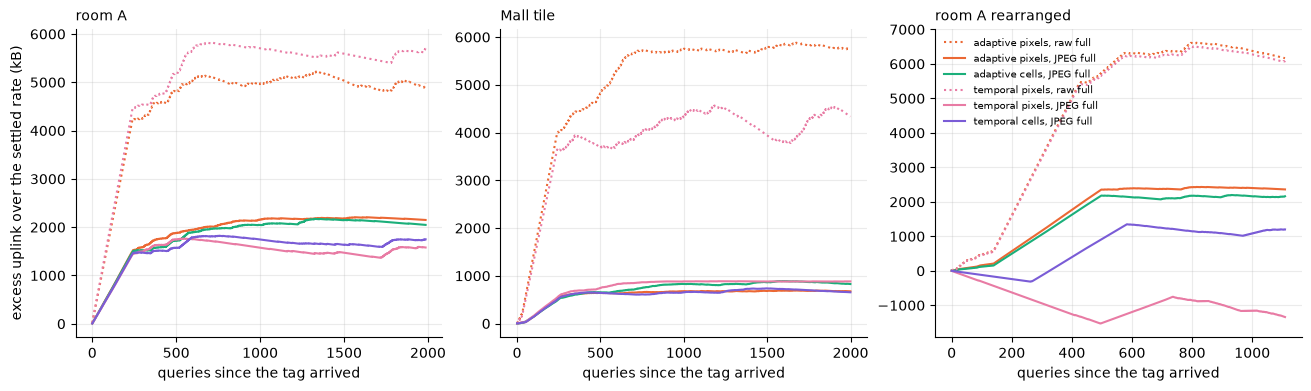

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for ax, r in zip(axs, ROOMS):
    for name, d in runs.items():
        if not name.startswith(('adaptive', 'temporal')):
            continue
        b = d[d.room == r].up_bytes.values.astype(float); settled = b[len(b) // 2:].mean()
        c, ls = STYLE[name]
        ax.plot(np.cumsum(b - settled) / 1e3, color=c, ls=ls, lw=1.5, label=name)
    ax.set_title(ROOM_NAME[r], loc='left', fontsize=10)
    ax.set_xlabel('queries since the tag arrived'); ax.grid(alpha=0.25)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
axs[0].set_ylabel('excess uplink over the settled rate (kB)')
axs[-1].legend(frameon=False, fontsize=7.5)
plt.show()

## 3. Static room: does the cost per query keep falling?

One room replayed 6× with state kept (`static_room.py`), identical frames each pass (best case). The curves are the cumulative excess over the last pass's rate; a curve that flattens means the loop has stopped paying for learning. `relaxed_*` share the `relaxed` check schedule; `relaxed_temporal`, `relaxed_smooth` and `relaxed_anomaly` use `TemporalServer` (section 4).

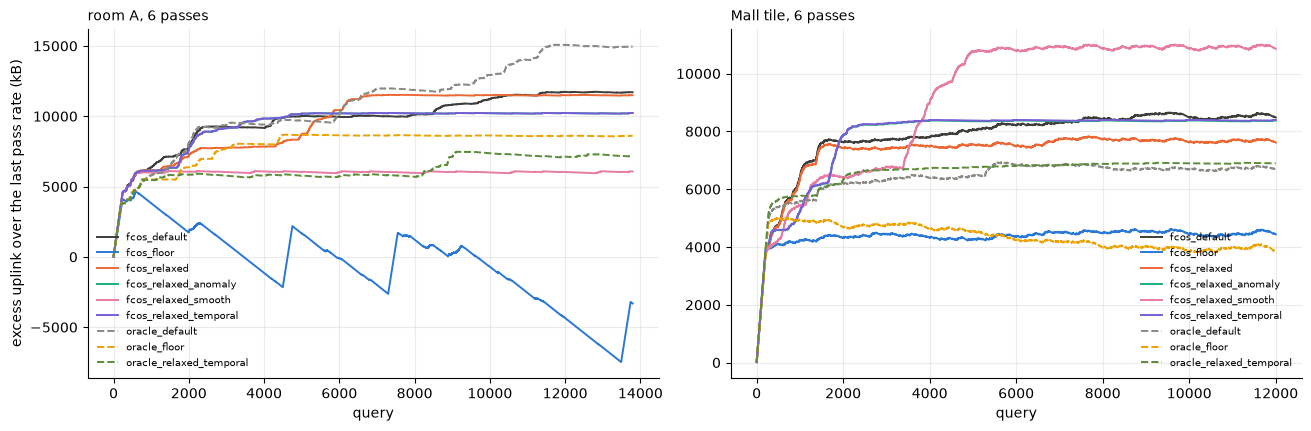

In [5]:
SR_RUNS = sorted(f.stem for f in SR.glob('*.npz') if '.tmp' not in f.name)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), constrained_layout=True)
rows = []
PAL = [INK, BLUE, ORANGE, AQUA, MAGENTA, '#7a5cd6', GRAY, '#eda100', '#5b8c3a']
for ax, room in zip(axs, ('A', 'mall')):
    names = [n for n in SR_RUNS if n.startswith(room + '_')]
    for c, n in zip(PAL * 2, names):
        d, meta = load(SR / f'{n}.npz')
        b = d.up_bytes.values.astype(float)
        last = b[d['pass'].values == d['pass'].max()].mean()
        ax.plot(np.cumsum(b - last) / 1e3, color=c, lw=1.4, ls='--' if 'oracle' in n else '-', label=n.split('_', 1)[1])
        for p, g in d.groupby('pass'):
            rows.append(dict(run=n, pass_=p, balanced_acc=balanced_accuracy(g), bytes_per_query=g.up_bytes.mean()))
    ax.set_title(f'{ROOM_NAME[room]}, 6 passes', loc='left', fontsize=10)
    ax.set_xlabel('query'); ax.grid(alpha=0.25)
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.legend(frameon=False, fontsize=7.5)
axs[0].set_ylabel('excess uplink over the last pass rate (kB)')
plt.show()
P = pd.DataFrame(rows)
P.pivot_table(index='run', columns='pass_', values=['balanced_acc', 'bytes_per_query']).style.format('{:.3f}', subset='balanced_acc').format('{:,.0f}', subset='bytes_per_query')

## 4. Prediction on the server: `TemporalServer`

`TieredServer` judges each code reply alone. But presence persists: in the switch stream the true label changes on 3–6% of consecutive PIROPO queries, while the code's own answer flips on 14–23%. `semwisp.server.TemporalServer` keeps a belief P(person now | everything received), a two-state hidden Markov filter:
* before each reply the belief relaxes towards 0.5 by the change rate r, **learned per room** from pairs of teacher labels;
* the code reply multiplies the odds by its likelihood ratio (the decoder output's two class Gaussians, from the learner), a thumbnail by its calibrated odds, and a teacher label resets it;
* an uncertain-answer thumbnail is asked for when the *belief* is unsure, not the single logit;
* the anomaly trigger (full frame) fires when the share of set bits is unlikely under **both** classes (above mean + 4 sd of each, from the learner's per-class bit rates), instead of a fixed 40%.

Static room, first and last pass, with the ablation (`relaxed_smooth`: belief only; `relaxed_anomaly`: learned trigger only):

In [6]:
cmp = []
for n in SR_RUNS:
    if 'relaxed' not in n:
        continue
    d, meta = load(SR / f'{n}.npz')
    for p, g in d.groupby('pass'):
        if p in (1, d['pass'].max()):
            cmp.append(dict(run=n, pass_=p, balanced_acc=balanced_accuracy(g), bytes_per_query=g.up_bytes.mean(),
                            full_rate=g.explored.mean(), anomaly_rate=g.anomaly.mean(), thumb_rate=g.thumbed.mean()))
pd.DataFrame(cmp).set_index(['run', 'pass_']).style.format('{:.3f}').format('{:,.0f}', subset='bytes_per_query')

Tiered against temporal on the streams of `tiered_checks.py` (same learner, teacher and frames). `settled_*` is the second half of each part.

In [7]:
PAIRS = [('switch_fcos_online_pixels_cal_tiered_b200', 'switch_fcos_online_pixels_cal_temporal_b200'),
         ('switch_fcos_online_cells_cal_tiered_b200', 'switch_fcos_online_cells_cal_temporal_b200'),
         ('switch_fcos_jpeg_online_pixels_cal_tiered_b200', 'switch_fcos_jpeg_online_pixels_cal_temporal_b200'),
         ('switch_fcos_jpeg_online_cells_cal_tiered_b200', 'switch_fcos_jpeg_online_cells_cal_temporal_b200'),
         ('switch_oracle_online_pixels_cal_tiered_b200', 'switch_oracle_online_pixels_cal_temporal_b200'),
         ('switch_oracle_online_cells_cal_tiered_b200', 'switch_oracle_online_cells_cal_temporal_b200'),
         ('piropo_fcos_online_pixels_cal_tiered_b200', 'piropo_fcos_online_pixels_cal_temporal_b200'),
         ('piropo_fcos_online_cells_cal_tiered_b200', 'piropo_fcos_online_cells_cal_temporal_b200')]
rows = []
for a, b in PAIRS:
    if not (TC / f'{b}.npz').exists():
        print('missing', b); continue
    for check, run in (('tiered', a), ('temporal', b)):
        d, meta = load(TC / f'{run}.npz')
        d['part'] = d.seq.map(ROOM) if run.startswith('switch') else 'pass ' + d['pass'].astype(str)
        for part, g in list(d.groupby('part', sort=False)) + [('whole', d)]:
            n = len(g)
            rows.append(dict(config=run.replace(f'_{check}_b200', ''), check=check, part=part,
                             balanced_acc=balanced_accuracy(g), bytes_per_query=g.up_bytes.mean(),
                             settled_acc=balanced_accuracy(g.iloc[n // 2:]), settled_bytes=g.up_bytes.iloc[n // 2:].mean()))
TT = pd.DataFrame(rows)
TT.pivot_table(index=['config', 'part'], columns='check', values=['balanced_acc', 'bytes_per_query', 'settled_acc', 'settled_bytes'], sort=False)\
  .style.format('{:.3f}').format('{:,.0f}', subset=['bytes_per_query', 'settled_bytes'])

## Findings

**Cumulative bits (sections 1–2, switch stream, one pass).**
* With JPEG full frames the adaptive loop's cumulative uplink falls below a non-adaptive JPEG q88 tag's at **query 244 and stays below** (pixels 6.6 MB, cells 7.4 MB against 25.7 MB over 5,097 queries), at 0.882–0.884 balanced accuracy against 0.921. With raw full frames it only gets there at query 4,960: JPEG full frames are what make the learning phase affordable.
* The **price of learning a room** (excess over the room's settled rate) is 0.7–2.4 MB, i.e. **230–360 JPEG q88 frames** of that room (pixels / cells, JPEG full frames). 90% of it is paid within 320–750 queries of arriving. This is the readaptation cost in bits; it is a steadier number than the recovery time of `readaptation.ipynb` (50–1,700 queries).
* Room A's second half is *less* accurate than its first (0.82–0.83 against 0.87–0.89): the first half includes the bootstrap, answered by the teacher on full frames.

**`TemporalServer` in a static room (sections 3–4, 6 passes, FCOS).** Last pass, against `relaxed` (same check schedule):
* Mall tile: **0.938 at 75 B/query against 0.909 at 944** (12× fewer bytes and more accurate). The accuracy drift over identical passes (0.935 → 0.909) is gone: 0.938–0.939 from pass 2 on. True labels: 0.943 at 73 B.
* Room A: **0.906 at 57 B/query against 0.890 at 101**.
* Ablation: the **learned anomaly trigger does most of it** (Mall 0.940 at 124 B, room A 0.906 at 66 B; anomaly-triggered full frames 4.6% → 0% of Mall queries). The belief then cuts thumbnails (Mall 48% → 23%, room A 6.6% → 1.6% of queries). The belief alone does not help: in the Mall the fixed trigger keeps firing (1,109 B), and in room A it locked in a weak code (0.765; the code's own answers score 0.760, the belief follows them; scheduled thumbnail checks agreed with it, so the interval rose to 250 and it was never relearned).
* PIROPO stream, pass 2: pixels 0.896 at 577 B against 0.894 at 741; cells **0.916 at 252 B against 0.900 at 864**.

**But it is worse across moves (switch stream).** Whole stream, FCOS on JPEG full frames: 0.834 / 0.837 against 0.882 / 0.884 (pixels / cells); true labels 0.860 / 0.830 against 0.898 / 0.888. The loss is mostly right after the second move (room A rearranged, first half 0.63 against 0.87). Cause: the anomaly threshold learned in the Mall (where people set many bits) is too high to fire when the tag moves on: no anomaly in the first 30 queries of the rearranged room (8 with the fixed trigger), so the move is detected at query 497 instead of 140. A threshold on *how many* bits are set cannot tell a busy room from a new room.

**Next.** Measure surprise as the code's likelihood under the room model, not its bit count: −log p(bits | class) with the learner's per-bit rates, scored against its own running distribution, and fire when it is high under both classes for consecutive queries. A move sets bits that neither class sets; a Mall crowd sets the bits people usually set. Until then, report `TemporalServer` for settled rooms only.

Two fixes made along the way: (1) a one-query anomaly is answered but not learned from (`hold_glitches`): a corrupted room A frame (test1, every-2nd-frame index 74, flat gray lower half, missed by `piropo.flag_bad`) otherwise made the learner restart from that frame; (2) the code's likelihood ratio uses one pooled variance (two variances make it non-monotone). The superseded first-version runs are not kept in `results/`.